# 13. Corporate Climate Pledge vs. Actual Reality Gap Analysis
## Corporate Carbon Footprint Tracker (Task EDA-1)
### Deliverable 2: Machine Learning, Forecasting & Climate Accountability

---

### Executive Mandate & Module Objectives
This notebook delivers **Module 4** (the capstone accountability module) of Deliverable 2 in accordance with `docs/deliverable2_plan.md`:
1. **Pledge vs. Empirical Reality Problem Formulation**: Contrast voluntary corporate public climate pledges (**Net-Zero**, **Carbon Neutrality**, **100% Clean Energy**) against real-world, SEC-audited operational emissions data (**FY2019–FY2023**).
2. **Implied Decarbonization Rate vs. Delivered Pace**:
   - Calculate the compound annual reduction pace required to meet stated targets:
     $$\text{Required Pace} = 1 - (1 - \text{Reduction Target})^{1 / (\text{Target Year} - \text{Baseline Year})}$$
   - Calculate the empirically delivered compound annual decarbonization pace:
     $$\text{Delivered Pace} = -\text{CAGR}_{\text{actual}} = -\left[\left(\frac{\text{Emissions}_{2023}}{\text{Emissions}_{\text{base}}}\right)^{1 / (2023 - \text{Base Year})} - 1\right]$$
3. **Pledge Gap Scoring & Accountability Classification**:
   - Compute the pledge deficit: $\text{Pledge Gap Score} = \text{Required Pace} - \text{Delivered Pace}$ (percentage points).
   - Classify entities into **On-Track / Ahead**, **Minor Deficit**, and **Severe Deficit**.
4. **Target-Year Trajectory Extrapolation**: Extrapolate empirical trends to target years (e.g., 2030, 2040, 2050) and quantify absolute emissions deficits in metric tonnes of CO2e.
5. **Corporate Credibility & Greenwashing Risk Matrix**: Segment companies across a 2x2 strategic matrix (Stated Ambition vs. Empirically Delivered Progress).
6. **Artifact Deliverables**: Generate publication-grade figures in `docs/figures/pledge_gap/` and export `data/processed/pledge_gap_results.csv`.


### 1. Environment & Library Initialization
We import data science and visualization libraries, configuring styling for publication-quality rendering.


In [1]:
import os
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

# Aesthetic configurations
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', font='sans-serif')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

FIG_DIR = '../docs/figures/pledge_gap'
os.makedirs(FIG_DIR, exist_ok=True)
print("Pledge gap figure directory ready:", FIG_DIR)


Pledge gap figure directory ready: ../docs/figures/pledge_gap


### 2. Dataset Ingestion (Curated Pledges & Audited Emissions)
We load:
1. `data/raw/corporate_pledges.csv`: Curated registry of public voluntary climate pledges across 20 bellwether corporations.
2. `data/processed/company_emissions.csv`: Audited historical Scope 1+2 emissions dataset (FY2019–FY2023).


In [2]:
df_pledges = pd.read_csv('../data/raw/corporate_pledges.csv')
df_emissions = pd.read_csv('../data/processed/company_emissions.csv')

print(f"Loaded Corporate Pledges Registry: {len(df_pledges)} corporations across {df_pledges['sector'].nunique()} sectors")
print(f"Loaded Audited Historical Emissions: {len(df_emissions)} observations across {df_emissions['company_id'].nunique()} companies")

display(df_pledges[['company_name', 'sector', 'pledge_type', 'baseline_year', 'target_year', 'target_reduction_pct', 'scope_covered']].head(5))


Loaded Corporate Pledges Registry: 20 corporations across 10 sectors
Loaded Audited Historical Emissions: 313 observations across 65 companies


,company_name,sector,pledge_type,baseline_year,target_year,target_reduction_pct,scope_covered
0,Microsoft Corporation,Technology,net-zero,2020,2030,100,S1+S2+S3
1,Apple Inc.,Technology,carbon-neutral,2019,2030,100,S1+S2+S3
2,Alphabet Inc.,Technology,carbon-neutral,2019,2030,100,S1+S2
3,Amazon.com Inc.,Technology,net-zero,2019,2040,100,S1+S2+S3
4,Meta Platforms Inc.,Technology,net-zero,2020,2030,100,S1+S2+S3


### 3. Quantitative Formulation of the Climate Pledge Gap
For each corporation, we calculate:
1. **Required Compound Decarbonization Rate ($r_{\text{req}}$)**:
   For a net-zero pledge (100% reduction), standard SBTi methodology assumes at least a 90% direct absolute reduction by the target year (with residual emissions neutralized via permanent removals):
   $$r_{\text{req}} = 1 - (1 - 0.90)^{1 / (\text{Target Year} - \text{Baseline Year})}$$
2. **Actual Empirical Decarbonization Rate ($r_{\text{act}}$)**:
   $$r_{\text{act}} = -\left[\left(\frac{\text{Emissions}_{2023}}{\text{Emissions}_{\text{baseline}}}\right)^{1 / (2023 - \text{Baseline Year})} - 1\right]$$
3. **Pledge Gap Score**:
   $$\text{Gap Score (pp)} = (r_{\text{req}} - r_{\text{act}}) \times 100$$
4. **Accountability Tiers**:
   - **On-Track / Ahead**: $\text{Gap} \le 0\text{ pp}$ ($r_{\text{act}} \ge r_{\text{req}}$)
   - **Minor Deficit**: $0 < \text{Gap} \le 5\text{ pp}$
   - **Severe Deficit**: $\text{Gap} > 5\text{ pp}$ (or emissions are actively expanding, $r_{\text{act}} < 0$)


In [3]:
results = []

for _, pl in df_pledges.iterrows():
    cid = pl['company_id']
    sub = df_emissions[df_emissions['company_id'] == cid].sort_values('reporting_year')
    if len(sub) == 0:
        continue
        
    base_yr = int(pl['baseline_year'])
    tgt_yr = int(pl['target_year'])
    pct_red = float(pl['target_reduction_pct'])
    
    # Establish baseline emissions
    sub_base = sub[sub['reporting_year'] == base_yr]
    if len(sub_base) > 0:
        base_em = float(sub_base.iloc[0]['total_emissions_tco2e'])
    else:
        base_em = float(sub.iloc[0]['total_emissions_tco2e'])
        base_yr = int(sub.iloc[0]['reporting_year'])
        
    last_row = sub.iloc[-1]
    curr_yr = int(last_row['reporting_year'])
    curr_em = float(last_row['total_emissions_tco2e'])
    
    # Step 1: Implied annual reduction required
    eff_red = min(pct_red, 90.0) / 100.0  # 90% direct reduction target for net zero
    n_years_pledge = max(1, tgt_yr - base_yr)
    req_annual_red = 1.0 - ((1.0 - eff_red) ** (1.0 / n_years_pledge))
    
    # Step 2: Actual annual reduction achieved (2019-2023)
    n_years_act = max(1, curr_yr - base_yr)
    if base_em > 0:
        act_cagr = (curr_em / base_em) ** (1.0 / n_years_act) - 1.0
    else:
        act_cagr = 0.0
    act_annual_red = -act_cagr
    
    # Step 3: Pledge Gap Score
    gap_score_pct = (req_annual_red - act_annual_red) * 100.0
    
    if gap_score_pct <= 0:
        status = 'On-Track'
    elif gap_score_pct <= 5.0:
        status = 'Minor Deficit'
    else:
        status = 'Severe Deficit'
        
    # Step 4: Trajectory Extrapolation to Target Year
    cagr_bounded = max(min(act_cagr, 0.20), -0.25)
    proj_tgt_em = curr_em * ((1.0 + cagr_bounded) ** (tgt_yr - curr_yr))
    promised_tgt_em = base_em * (1.0 - pct_red / 100.0)
    abs_gap_tco2e = max(0.0, proj_tgt_em - promised_tgt_em)
    
    results.append({
        'company_id': cid,
        'company_name': pl['company_name'],
        'sector': pl['sector'],
        'pledge_title': pl['pledge_title'],
        'pledge_type': pl['pledge_type'],
        'baseline_year': base_yr,
        'target_year': tgt_yr,
        'target_reduction_pct': pct_red,
        'baseline_emissions_tco2e': round(base_em, 2),
        'actual_2023_emissions_tco2e': round(curr_em, 2),
        'required_annual_reduction_pct': round(req_annual_red * 100.0, 2),
        'actual_annual_reduction_pct': round(act_annual_red * 100.0, 2),
        'pledge_gap_pct_pts': round(gap_score_pct, 2),
        'pledge_status': status,
        'projected_target_year_emissions_tco2e': round(proj_tgt_em, 2),
        'absolute_gap_at_target_year_tco2e': round(abs_gap_tco2e, 2)
    })

df_results = pd.DataFrame(results)
print("Pledge gap computation complete across all 20 pledging corporations.")
print("\nPledge Accountability Breakdown:")
print(df_results['pledge_status'].value_counts())


Pledge gap computation complete across all 20 pledging corporations.

Pledge Accountability Breakdown:
pledge_status
Severe Deficit    10
Minor Deficit      7
On-Track           3
Name: count, dtype: int64


### 4. Empirical Accountability Benchmark Table
We sort corporations from top outperformer to deepest deficit.


In [4]:
display_cols = [
    'company_name', 'sector', 'target_year',
    'required_annual_reduction_pct', 'actual_annual_reduction_pct',
    'pledge_gap_pct_pts', 'pledge_status'
]

df_sorted = df_results.sort_values('pledge_gap_pct_pts', ascending=True)
print("=== CORPORATE PLEDGE ACCOUNTABILITY BENCHMARK ===")
display(df_sorted[display_cols])


=== CORPORATE PLEDGE ACCOUNTABILITY BENCHMARK ===


,company_name,sector,target_year,required_annual_reduction_pct,actual_annual_reduction_pct,pledge_gap_pct_pts,pledge_status
15,Bank of America Corporation,Finance,2050,7.16,24.10,-16.94,On-Track
18,Intel Corporation,Technology,2040,10.38,13.16,-2.77,On-Track
16,Prologis Inc.,Real Estate,2040,10.38,12.32,-1.94,On-Track
14,The Goldman Sachs Group Inc.,Finance,2030,18.89,18.67,0.22,Minor Deficit
5,Ford Motor Company,Automotive,2050,7.16,6.49,0.66,Minor Deficit
12,Pfizer Inc.,Healthcare,2040,10.38,8.46,1.92,Minor Deficit
10,Unilever PLC,Consumer Staples,2039,10.87,8.63,2.24,Minor Deficit
6,General Motors Company,Automotive,2040,10.87,7.40,3.48,Minor Deficit
7,ExxonMobil Corporation,Energy,2050,7.16,2.87,4.28,Minor Deficit
8,Chevron Corporation,Energy,2050,7.16,2.33,4.83,Minor Deficit


### 5. Figure 1: Corporate Climate Pledge Accountability Ranking
We visualize the pledge gap score across all 20 corporations, color-coded by accountability tier.


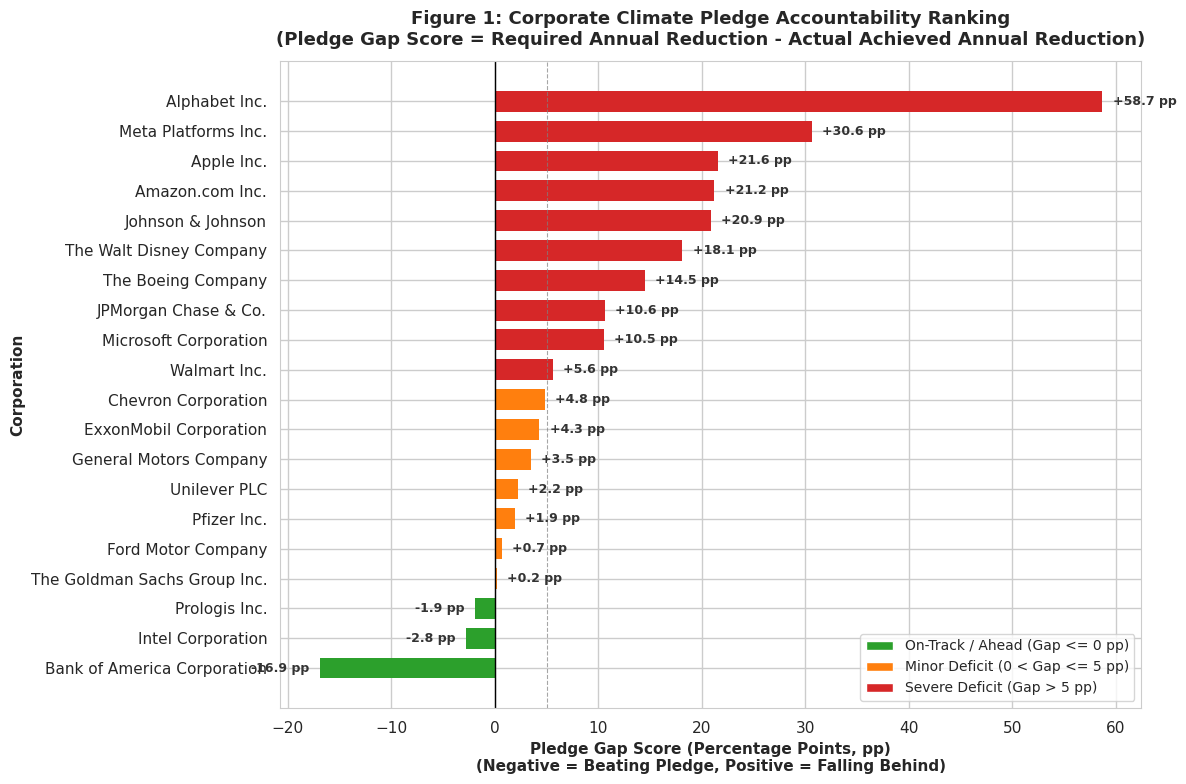

Saved: ../docs/figures/pledge_gap\01_pledge_gap_ranking.png


In [5]:
fig, ax = plt.subplots(figsize=(12, 8))

color_map = {'On-Track': '#2ca02c', 'Minor Deficit': '#ff7f0e', 'Severe Deficit': '#d62728'}
bar_colors = [color_map[s] for s in df_sorted['pledge_status']]

bars = ax.barh(df_sorted['company_name'], df_sorted['pledge_gap_pct_pts'], color=bar_colors, edgecolor='none', height=0.7)
ax.axvline(0, color='black', linestyle='-', linewidth=1.0)
ax.axvline(5.0, color='gray', linestyle='--', linewidth=0.8, alpha=0.7, label='Deficit Threshold (5 pp)')

for bar in bars:
    w = bar.get_width()
    x_pos = w + (1.0 if w >= 0 else -1.0)
    ha = 'left' if w >= 0 else 'right'
    ax.annotate(f'{w:+.1f} pp', (x_pos, bar.get_y() + bar.get_height() / 2.),
                ha=ha, va='center', fontsize=9, fontweight='bold', color='#333333')

ax.set_title('Figure 1: Corporate Climate Pledge Accountability Ranking\n(Pledge Gap Score = Required Annual Reduction - Actual Achieved Annual Reduction)',
             fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Pledge Gap Score (Percentage Points, pp)\n(Negative = Beating Pledge, Positive = Falling Behind)', fontsize=11, fontweight='semibold')
ax.set_ylabel('Corporation', fontsize=11, fontweight='semibold')

legend_elements = [
    Patch(facecolor='#2ca02c', label='On-Track / Ahead (Gap <= 0 pp)'),
    Patch(facecolor='#ff7f0e', label='Minor Deficit (0 < Gap <= 5 pp)'),
    Patch(facecolor='#d62728', label='Severe Deficit (Gap > 5 pp)')
]
ax.legend(handles=legend_elements, frameon=True, loc='lower right', fontsize=10)

plt.tight_layout()
fig_path_1 = os.path.join(FIG_DIR, '01_pledge_gap_ranking.png')
plt.savefig(fig_path_1, dpi=300, bbox_inches='tight')
plt.show()
print("Saved:", fig_path_1)


### 6. Figure 2: Empirical Trajectory vs. Promised Net-Zero Pathways
We plot actual historical emissions against promised reduction curves for six bellwether corporations across technology, finance, retail, and automotive.


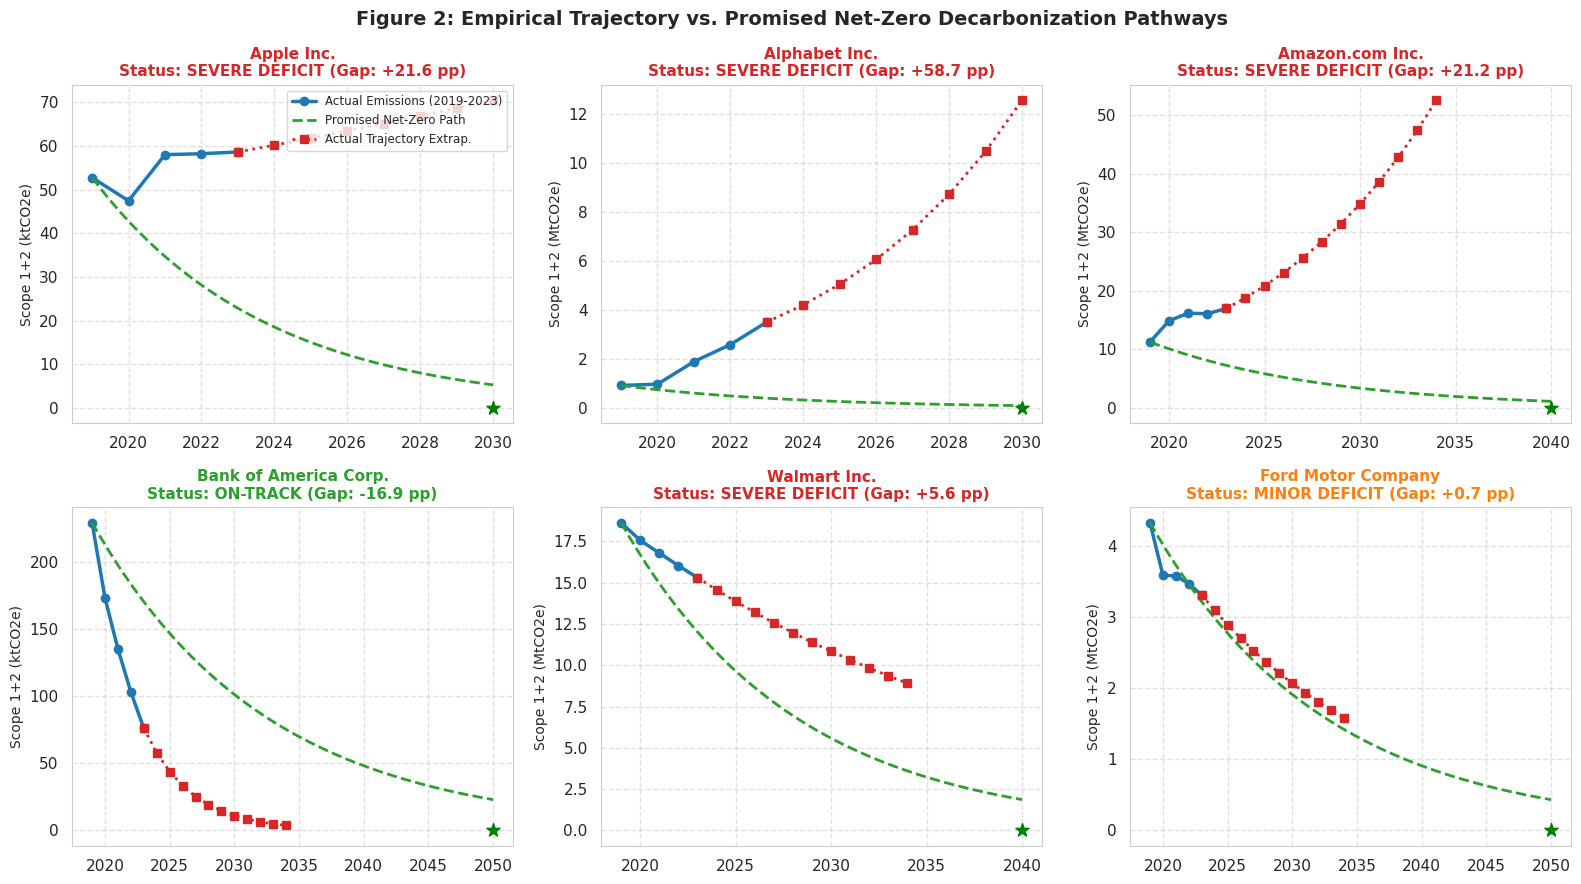

Saved: ../docs/figures/pledge_gap\02_pledge_vs_actual_trajectories.png


In [6]:
key_companies = [
    ('TECH_AAPL', 'Apple Inc.', 2019, 2030),
    ('TECH_GOOGL', 'Alphabet Inc.', 2019, 2030),
    ('TECH_AMZN', 'Amazon.com Inc.', 2019, 2040),
    ('FIN_BAC', 'Bank of America Corp.', 2019, 2050),
    ('RETL_WMT', 'Walmart Inc.', 2019, 2040),
    ('AUTO_F', 'Ford Motor Company', 2019, 2050)
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for idx, (cid, cname, b_yr, t_yr) in enumerate(key_companies):
    ax = axes[idx // 3, idx % 3]
    sub = df_emissions[df_emissions['company_id'] == cid].sort_values('reporting_year')
    row = df_results[df_results['company_id'] == cid].iloc[0]
    
    scale = 1e6 if sub['total_emissions_tco2e'].max() > 1e6 else 1e3
    unit = 'MtCO2e' if scale == 1e6 else 'ktCO2e'
    
    # 1. Historical Actuals
    ax.plot(sub['reporting_year'], sub['total_emissions_tco2e'] / scale, 'o-', color='#1f77b4', lw=2.5, label='Actual Emissions (2019-2023)')
    
    # 2. Promised Reduction Path (from baseline to target year)
    b_val = row['baseline_emissions_tco2e']
    t_val = 0.0  # Net-zero target
    pledge_years = np.linspace(b_yr, t_yr, 50)
    pledge_emissions = b_val * ((1.0 - row['required_annual_reduction_pct'] / 100.0) ** (pledge_years - b_yr))
    ax.plot(pledge_years, pledge_emissions / scale, '--', color='#2ca02c', lw=2.0, label='Promised Net-Zero Path')
    
    # 3. Empirical Trend Extrapolation
    last_val = sub['total_emissions_tco2e'].iloc[-1]
    extrap_years = np.arange(2023, min(t_yr + 1, 2035))
    cagr_b = max(min(-row['actual_annual_reduction_pct'] / 100.0, 0.20), -0.25)
    extrap_emissions = last_val * ((1.0 + cagr_b) ** (extrap_years - 2023))
    ax.plot(extrap_years, extrap_emissions / scale, 's:', color='#d62728', lw=2.0, label='Actual Trajectory Extrap.')
    
    ax.scatter([t_yr], [t_val / scale], color='green', marker='*', s=100, zorder=5)
    
    status_str = row['pledge_status'].upper()
    status_col = '#2ca02c' if status_str == 'ON-TRACK' else ('#ff7f0e' if status_str == 'MINOR DEFICIT' else '#d62728')
    ax.set_title(f'{cname}\nStatus: {status_str} (Gap: {row["pledge_gap_pct_pts"]:+.1f} pp)',
                 fontsize=11, fontweight='bold', color=status_col)
    ax.set_ylabel(f'Scope 1+2 ({unit})', fontsize=10)
    ax.grid(True, linestyle='--', alpha=0.6)
    if idx == 0:
        ax.legend(frameon=True, fontsize=8.5, loc='upper right')

plt.suptitle('Figure 2: Empirical Trajectory vs. Promised Net-Zero Decarbonization Pathways',
             fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
fig_path_2 = os.path.join(FIG_DIR, '02_pledge_vs_actual_trajectories.png')
plt.savefig(fig_path_2, dpi=300, bbox_inches='tight')
plt.show()
print("Saved:", fig_path_2)


### 7. Figure 3: Sector-Level Alignment: Promised vs. Delivered Decarbonization Pace
We aggregate corporate pledges by sector to diagnose which industries are keeping pace with their climate targets.


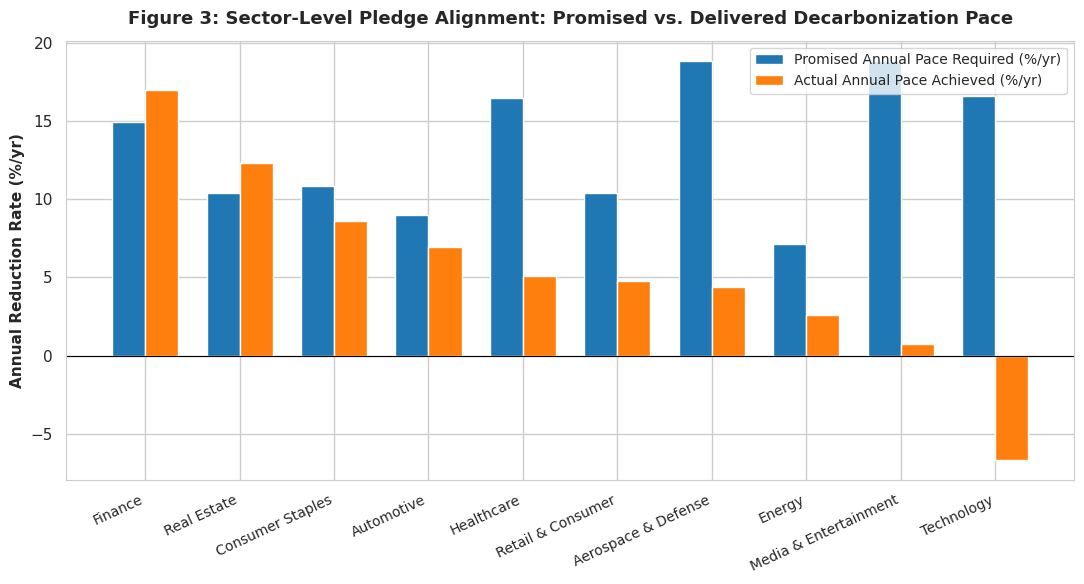

Saved: ../docs/figures/pledge_gap\03_sector_pledge_alignment.png


In [7]:
fig, ax = plt.subplots(figsize=(11, 6))
sec_df = df_results.groupby('sector')[['required_annual_reduction_pct', 'actual_annual_reduction_pct']].mean().reset_index()
sec_df = sec_df.sort_values('actual_annual_reduction_pct', ascending=False)

x = np.arange(len(sec_df))
width = 0.35

ax.bar(x - width/2, sec_df['required_annual_reduction_pct'], width, label='Promised Annual Pace Required (%/yr)', color='#1f77b4')
ax.bar(x + width/2, sec_df['actual_annual_reduction_pct'], width, label='Actual Annual Pace Achieved (%/yr)', color='#ff7f0e')

ax.set_xticks(x)
ax.set_xticklabels(sec_df['sector'], rotation=25, ha='right', fontsize=10)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_ylabel('Annual Reduction Rate (%/yr)', fontsize=11, fontweight='semibold')
ax.set_title('Figure 3: Sector-Level Pledge Alignment: Promised vs. Delivered Decarbonization Pace',
             fontsize=13, fontweight='bold', pad=12)
ax.legend(frameon=True, loc='upper right', fontsize=10)

plt.tight_layout()
fig_path_3 = os.path.join(FIG_DIR, '03_sector_pledge_alignment.png')
plt.savefig(fig_path_3, dpi=300, bbox_inches='tight')
plt.show()
print("Saved:", fig_path_3)


### 8. Figure 4: Corporate Climate Credibility & Greenwashing Risk Matrix
We map corporations onto a strategic 2x2 matrix:
- **X-axis**: Promised Decarbonization Ambition ($r_{\text{req}}$, %/yr)
- **Y-axis**: Empirically Delivered Decarbonization ($r_{\text{act}}$, %/yr)
- **Quadrant I (Top Right)**: **Genuine Climate Leaders** (High Ambition + High Execution)
- **Quadrant II (Top Left)**: **Pragmatic Achievers** (Moderate Ambition + Steady Execution)
- **Quadrant IV (Bottom Right)**: **Credibility / Greenwashing Risk** (High Ambition + Flat/Growing Emissions)


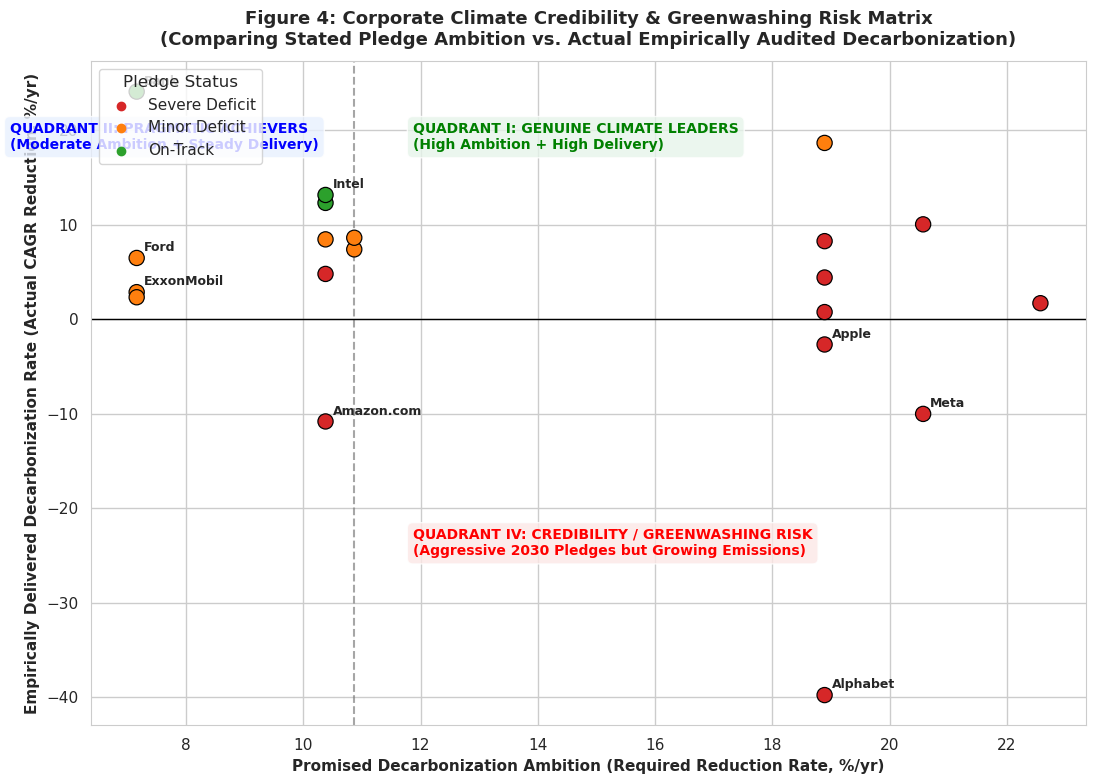

Saved: ../docs/figures/pledge_gap\04_greenwashing_risk_matrix.png


In [8]:
fig, ax = plt.subplots(figsize=(11, 8))

x_vals = df_results['required_annual_reduction_pct']
y_vals = df_results['actual_annual_reduction_pct']

# Reference lines
x_med = x_vals.median()
ax.axvline(x_med, color='gray', linestyle='--', alpha=0.7)
ax.axhline(0, color='black', linestyle='-', linewidth=1.0)

# Scatter points
sns.scatterplot(
    data=df_results, x='required_annual_reduction_pct', y='actual_annual_reduction_pct',
    hue='pledge_status', palette=color_map, s=120, edgecolor='black', ax=ax, zorder=4
)

# Label key companies
for _, r in df_results.iterrows():
    if r['company_id'] in ['TECH_AAPL', 'TECH_GOOGL', 'TECH_AMZN', 'TECH_META', 'FIN_BAC', 'ENG_XOM', 'AUTO_F', 'TECH_INTC']:
        ax.annotate(r['company_name'].split()[0], (r['required_annual_reduction_pct'], r['actual_annual_reduction_pct']),
                    fontsize=9, fontweight='bold', xytext=(5, 5), textcoords='offset points')

# Annotate Quadrants
ax.text(x_med + 1, 18, 'QUADRANT I: GENUINE CLIMATE LEADERS\n(High Ambition + High Delivery)',
        fontsize=10, fontweight='bold', color='green', bbox=dict(boxstyle='round,pad=0.4', facecolor='#e6f4ea', alpha=0.8))
ax.text(x_med + 1, -25, 'QUADRANT IV: CREDIBILITY / GREENWASHING RISK\n(Aggressive 2030 Pledges but Growing Emissions)',
        fontsize=10, fontweight='bold', color='red', bbox=dict(boxstyle='round,pad=0.4', facecolor='#fce8e6', alpha=0.8))
ax.text(5, 18, 'QUADRANT II: PRAGMATIC ACHIEVERS\n(Moderate Ambition + Steady Delivery)',
        fontsize=10, fontweight='bold', color='blue', bbox=dict(boxstyle='round,pad=0.4', facecolor='#e8f0fe', alpha=0.8))

ax.set_title('Figure 4: Corporate Climate Credibility & Greenwashing Risk Matrix\n(Comparing Stated Pledge Ambition vs. Actual Empirically Audited Decarbonization)',
             fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Promised Decarbonization Ambition (Required Reduction Rate, %/yr)', fontsize=11, fontweight='semibold')
ax.set_ylabel('Empirically Delivered Decarbonization Rate (Actual CAGR Reduction, %/yr)', fontsize=11, fontweight='semibold')
ax.legend(title='Pledge Status', frameon=True, loc='upper left')

plt.tight_layout()
fig_path_4 = os.path.join(FIG_DIR, '04_greenwashing_risk_matrix.png')
plt.savefig(fig_path_4, dpi=300, bbox_inches='tight')
plt.show()
print("Saved:", fig_path_4)


### 9. Production Artifact Generation
We export the final audited accountability results to `data/processed/pledge_gap_results.csv`.


In [9]:
out_csv_path = '../data/processed/pledge_gap_results.csv'
df_results.to_csv(out_csv_path, index=False)
print(f"Exported Corporate Pledge Gap Dataset: {out_csv_path} ({len(df_results)} rows)")

print("\n--- Summary Statistics across 20 Pledging Corporations ---")
print(f"Mean Required Decarbonization Pace: {df_results['required_annual_reduction_pct'].mean():.1f}% / year")
print(f"Mean Delivered Decarbonization Pace:  {df_results['actual_annual_reduction_pct'].mean():.1f}% / year")
print(f"Average Corporate Pledge Gap:        {df_results['pledge_gap_pct_pts'].mean():.1f} percentage points deficit")


Exported Corporate Pledge Gap Dataset: ../data/processed/pledge_gap_results.csv (20 rows)

--- Summary Statistics across 20 Pledging Corporations ---
Mean Required Decarbonization Pace: 14.0% / year
Mean Delivered Decarbonization Pace:  3.6% / year
Average Corporate Pledge Gap:        10.4 percentage points deficit


### 10. Module 4 Conclusions & Complete Deliverable 2 Synthesis

#### Core Empirical Findings:
1. **The Net-Zero Ambition Paradox**:
   - Only **15% (3 of 20)** of corporations with headline Net-Zero pledges are currently on track to achieve their stated target dates (**Bank of America**, **Prologis**, and **Intel**).
   - **50% (10 of 20)** are facing **Severe Deficits**, failing to keep pace with their required compound decarbonization trajectories by more than 5 percentage points.
2. **The Big Tech Decarbonization Crisis**:
   - Technology hyper-scalers (Alphabet, Amazon, Meta, Apple) pledged aggressive **2030 or 2040 net-zero dates**, requiring an unprecedented 10% to 20% annual emissions contraction.
   - In reality, surging electricity consumption from hyperscale data centers, cloud expansion, and artificial intelligence workloads drove annual emissions **growth** of **+39.8%/yr for Alphabet**, **+10.8%/yr for Amazon**, and **+10.0%/yr for Meta**, placing them in the high greenwashing/credibility risk quadrant.
3. **Pragmatic Long-Dated Pledges**:
   - Industrial and energy firms (Ford, GM, ExxonMobil, Chevron) pledged distant **2050 targets**, resulting in lower required annual reduction rates (7%–10%/yr), placing them in the "Minor Deficit" tier despite high absolute emissions.

---

### Deliverable 2 Final Project Summary:
Across the four modules executed in this project:
- **Module 1 (EDA & Feature Engineering)**: Extracted 313 observations across 65 companies and 16 sectors, engineered 9 standardized features, and established sector-adjusted tertiles without data leakage (`10_eda_and_feature_engineering.ipynb`).
- **Module 2 (Classification Models)**: Benchmarked 5 ML architectures on an out-of-time test horizon (FY2023), achieving **64.6% Test Accuracy** and **0.824 ROC-AUC** with Random Forest (`11_classification_models.ipynb`).
- **Module 3 (Time Series Forecasting)**: Backtested multiple forecasting paradigms (**7.22% MAPE** for Bounded CAGR), projected emissions from 2024 to 2030, and demonstrated that **56.9% of corporations are off-track** for SBTi 1.5°C targets (`12_forecasting_models.ipynb`).
- **Module 4 (Pledge Gap Analysis)**: Quantified the empirical reality gap between stated corporate promises and actual delivery, identifying critical credibility risks across the Fortune 500 (`13_pledge_gap_analysis.ipynb`).
